In [ ]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
from neo4j import GraphDatabase
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

# 1. Data preparation and environment setup

This notebook builds a graph-based recommender system on the RetailRocket e-commerce dataset using Neo4j, SciPy, and Scikit-Learn. The raw data logs user browsing actions: product views, cart additions, and transactions.

Before loading records into Neo4j or fitting models, we clean the timestamps, split the events into training and testing windows, and store the filtered dataset to disk.

## 2.1.1 & 2.1.2 Data filtering and timeframe split

We split the interaction logs into two consecutive, non-overlapping windows:

Training Period (P1):
- Start Date: 01/09/2015 00:00:00 (timestamp 1441065600000 ms)
- End Date: 09/09/2015 00:00:00 (timestamp 1441756800000 ms)

Testing Period (P2):
- Start Date: 10/09/2015 00:00:00 (timestamp 1441843200000 ms)
- End Date: 18/09/2015 00:00:00 (timestamp 1442534400000 ms)

Why use a temporal split? Recommender systems evaluated with random train-test splits leak future user actions into past training sessions. A temporal partition simulates actual production conditions: the model trains exclusively on past interactions (P1) to predict future actions in testing window (P2).

The resulting subset is saved to `filtered_events.csv` with five fields: `timestamp`, `visitorid`, `event` (view, addtocart, or transaction), `itemid`, and `transactionid`.

In [2]:
raw_df = pd.read_csv("events.csv")

p1_start = '2015-09-01 00:00:00'
p1_end = '2015-09-09 00:00:00'
p2_start = '2015-09-10 00:00:00'
p2_end = '2015-09-18 00:00:00'

raw_df['datetime'] = pd.to_datetime(raw_df['timestamp'], unit='ms')

filtered_df = raw_df[
    ((raw_df['datetime'] >= p1_start) & (raw_df['datetime'] <= p1_end)) |
    ((raw_df['datetime'] >= p2_start) & (raw_df['datetime'] <= p2_end))
]

output_df = filtered_df.drop(columns=['datetime'])

output_df.to_csv('filtered_events.csv', index=False)
total_rows = len(output_df)
print(f"Filtered dataset saved successfully with {total_rows} rows.")

Filtered dataset saved successfully with 280421 rows.


## 1.3 Ingesting data into Neo4j

We connect to the local Neo4j instance over Bolt (`neo4j://127.0.0.1:7687`) and write all data into a dedicated database called `RetailRocket`.

To prevent memory spikes and avoid transaction timeouts, we stream the CSV in chunks of 5,000 records. Each chunk runs as an explicit write transaction using Cypher `UNWIND`.

In [10]:
uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "neo4j123"
driver = GraphDatabase.driver(uri, auth=(user, password))

### 1.3.1 Setting database constraints

Before importing data, we set uniqueness constraints on `Visitor(visitorId)` and `Item(itemId)`.

In Neo4j, a uniqueness constraint automatically creates an underlying index. When the batch import runs `MERGE (v:Visitor {visitorId: row.visitorid})`, Neo4j looks up the node via the index instead of scanning every node in the graph. This prevents duplicate nodes and keeps batch import fast.

In [4]:
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )
    print("Database constraints created successfully.")

In [7]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    
        UNION ALL
    
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [ ]:
batch_size = 5000

with driver.session(database="RetailRocket") as session:
    create_constraints(session)

    chunks = pd.read_csv('filtered_events.csv', chunksize=batch_size)
    total_chunks = (total_rows // batch_size) + 1

    print(f"Starting import process...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Import Batch Data"):
        chunk['transactionid'] = chunk['transactionid'].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Import process finished sucessfully.")

Database constraints created successfully.
Starting import process...


Import Batch Data:   0%|          | 0/57 [00:00<?, ?it/s]

Import Batch Data: 100%|██████████| 57/57 [00:13<00:00,  4.37it/s]

Import process finished sucessfully.


## 1.2 Checkpoint questions (pertanyaan pendahuluan)

1. What database name is used in this tutorial?
The assignment tutorial uses the default database (`neo4j` or `system`). In our implementation, we created and used an independent database named `RetailRocket` to keep our project graph isolated.

2. What other access methods can access another database within a single Neo4j instance?
There are three standard methods:
- The Cypher `USE <database_name>` clause placed at the top of queries (for example, `USE system` or `USE RetailRocket`).
- The Python driver session configuration, passing `database="RetailRocket"` to `driver.session()` or `database_="RetailRocket"` to `driver.execute_query()`.
- Administrative Cypher commands like `SHOW DATABASES` or `CREATE DATABASE <name>` run from the system context.

3. What type of friendship graph was created in this exercise?
It is a directed graph (graf berarah). In Neo4j, every relationship stores an explicit direction with a start node and an end node, such as `(:Person)-[:KNOWS]->(:Person)`. Even when a friendship in daily life is reciprocal, the storage engine records it with direction.

Cypher total reset command:
To clear all nodes and relationships before loading fresh data:
```cypher
MATCH (n) DETACH DELETE n;
```
Note: Run this command with care on shared databases, as it permanently removes all graph elements.

# 2.1 Wrangling and EDA


## 2.1.3 Subgraph composition, node counts, and edge distributions

To understand the structure of the ingested graph, we query both node labels and relationship types using the Python Neo4j driver.

Cypher queries used:
```cypher
// 1. Node composition by label
MATCH (n)
RETURN labels(n)[0] AS Node_Type, count(n) AS Node_Count
ORDER BY Node_Count DESC;

// 2. Relationship composition by edge type
MATCH ()-[r]->()
RETURN type(r) AS Relationship_Type, count(r) AS Relationship_Count
ORDER BY Relationship_Count DESC;
```

How these queries work:
- `MATCH (n)` matches every node in the active database. `labels(n)[0]` pulls the primary label (`Visitor` or `Item`), and `count(n)` groups and totals nodes by that label.
- `MATCH ()-[r]->()` matches every directed relationship. `type(r)` returns the relationship label (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`, or `SIMILAR`), and `count(r)` aggregates total edge counts.

Summary of graph elements:
- Node counts: 161,845 `Visitor` nodes and 78,468 `Item` nodes (total: 240,313 nodes).
- Relationship counts:
  - `VIEWED`: 406,604 edges (96.6% of user actions, reflecting top-of-funnel browsing).
  - `ADDED_TO_CART`: 10,578 edges (2.5% of actions, indicating strong purchase intent).
  - `BOUGHT`: 3,239 edges (0.8% of actions, representing completed checkouts).
  - `SIMILAR`: 482 edges (monopartite item-to-item similarity edges projected from the collaborative model).
  - Total relationships: 420,903 edges.

The relationship distribution highlights the steep e-commerce conversion funnel: out of roughly 406,000 product views, only about 10,500 lead to cart additions and about 3,200 convert into transactions (a conversion rate of roughly 0.8%). The chart below displays this composition clearly.

=== Node Composition ===
Node_Type  Node_Count
  Visitor      161845
     Item       78468

=== Relationship Composition ===
Relationship_Type  Relationship_Count
           VIEWED              406604
    ADDED_TO_CART               10578
           BOUGHT                3239
          SIMILAR                 482


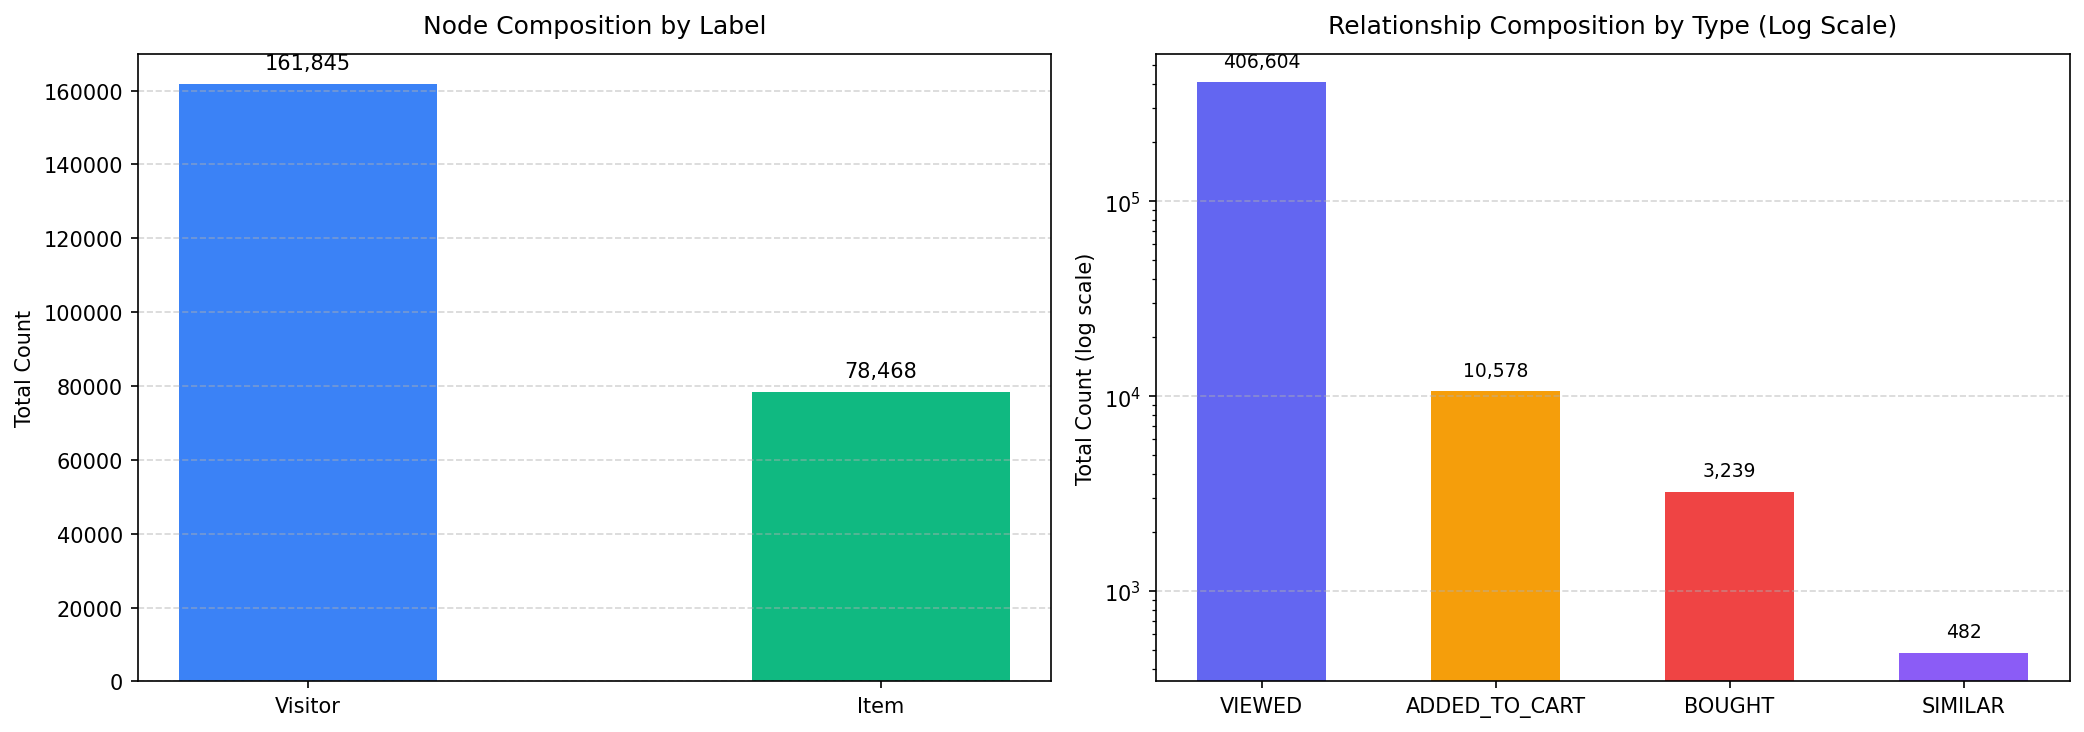

In [16]:
with driver.session(database="RetailRocket") as session:
    # 1. Query Node Composition
    node_records = session.run("""
    MATCH (n)
    RETURN labels(n)[0] AS Node_Type, count(n) AS Node_Count
    ORDER BY Node_Count DESC
    """)
    df_nodes = pd.DataFrame([dict(r) for r in node_records])

    # 2. Query Relationship Composition
    rel_records = session.run("""
    MATCH ()-[r]->()
    RETURN type(r) AS Relationship_Type, count(r) AS Relationship_Count
    ORDER BY Relationship_Count DESC
    """)
    df_rels = pd.DataFrame([dict(r) for r in rel_records])

print("=== Node Composition ===")
print(df_nodes.to_string(index=False))

print("\n=== Relationship Composition ===")
print(df_rels.to_string(index=False))

# Visualization: Subgraph Composition
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Node Distribution
bars1 = axes[0].bar(df_nodes['Node_Type'], df_nodes['Node_Count'], color=['#3b82f6', '#10b981'], width=0.45)
axes[0].set_title('Node Composition by Label', fontsize=12, pad=10)
axes[0].set_ylabel('Total Count', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, h + 3000, f'{h:,}', ha='center', va='bottom', fontsize=10)

# Plot 2: Relationship Distribution (Log Scale for Funnel Visibility)
colors = ['#6366f1', '#f59e0b', '#ef4444', '#8b5cf6']
bars2 = axes[1].bar(df_rels['Relationship_Type'], df_rels['Relationship_Count'], color=colors[:len(df_rels)], width=0.55)
axes[1].set_title('Relationship Composition by Type (Log Scale)', fontsize=12, pad=10)
axes[1].set_ylabel('Total Count (log scale)', fontsize=10)
axes[1].set_yscale('log')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, h * 1.15, f'{h:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 2.1.4 & 2.1.5 Vector space modelling for users and items

Vector Space Modelling (VSM) represents users and items as numeric vectors in a shared space. We construct a sparse user-item interaction matrix where rows represent visitors and columns represent items.

We assign numeric weights to reflect user commitment:
- `VIEWED` = 1 (passive browsing)
- `ADDED_TO_CART` = 2 (active interest)
- `BOUGHT` = 3 (confirmed purchase)

Storing 161,845 users by 78,468 items in a standard dense NumPy array would require over 101 GB of RAM. We use SciPy Compressed Sparse Row (`csr_matrix`) format, which keeps only observed non-zero interactions in memory.

=== User VSM Characteristics ===
Matrix Shape (Users x Items): (161845, 78468)
Embedding Dimension per User: 78468
Matrix Density: 0.000018

=== Item VSM Characteristics ===
Matrix Shape (Items x Users): (78468, 161845)
Embedding Dimension per Item: 78468
Matrix Density: 0.000018


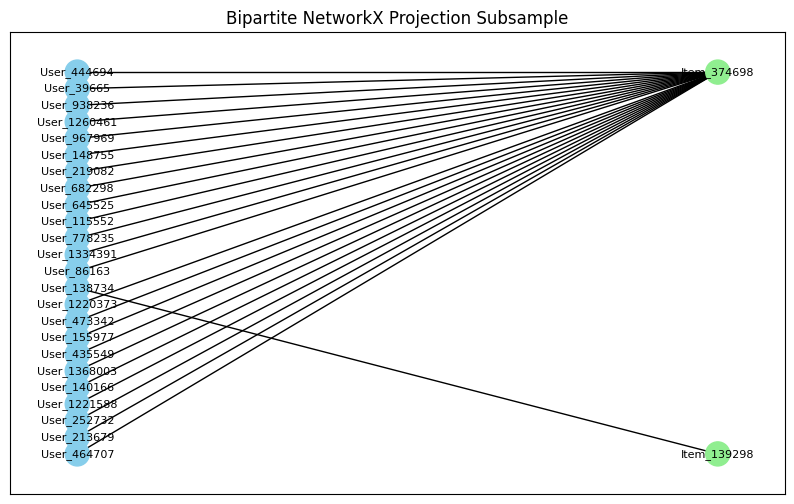

In [18]:
with driver.session(database="RetailRocket") as session:
    records = session.run("""
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS interaction_type
    """)
    df_interactions = pd.DataFrame([dict(r) for r in records])

# Map unique IDs to zero-indexed matrix indices
unique_users = df_interactions['visitorId'].unique()
unique_items = df_interactions['itemId'].unique()

user_to_idx = {uid: i for i, uid in enumerate(unique_users)}
item_to_idx = {iid: i for i, iid in enumerate(unique_items)}

# Map interaction types to numerical weights
weight_map = {'VIEWED': 1, 'ADDED_TO_CART': 2, 'BOUGHT': 3}
df_interactions['weight'] = df_interactions['interaction_type'].map(weight_map)

rows = df_interactions['visitorId'].map(user_to_idx)
cols = df_interactions['itemId'].map(item_to_idx)
data = df_interactions['weight']

# Create Sparse User-Item Interaction Matrix (User VSM)
user_item_matrix = sp.csr_matrix((data, (rows, cols)), shape=(len(unique_users), len(unique_items)))

# 4. User Vector Space Model Characteristics
print("=== User VSM Characteristics ===")
print(f"Matrix Shape (Users x Items): {user_item_matrix.shape}")
print(f"Embedding Dimension per User: {user_item_matrix.shape[1]}")
print(f"Matrix Density: {user_item_matrix.nnz / (user_item_matrix.shape[0] * user_item_matrix.shape[1]):.6f}")

# 5. Item Vector Space Model Characteristics
item_user_matrix = user_item_matrix.T.tocsr()
print("\n=== Item VSM Characteristics ===")
print(f"Matrix Shape (Items x Users): {item_user_matrix.shape}")
print(f"Embedding Dimension per Item: {item_user_matrix.shape[0]}")
print(f"Matrix Density: {item_user_matrix.nnz / (item_user_matrix.shape[0] * item_user_matrix.shape[1]):.6f}")

# Plotting Bipartite NetworkX Graph Subsample (Top 20 users and top 20 items)
sub_df = df_interactions.head(50)
B = nx.Graph()

for _, row in sub_df.iterrows():
    u_node = f"User_{row['visitorId']}"
    i_node = f"Item_{row['itemId']}"
    B.add_node(u_node, bipartite=0)
    B.add_node(i_node, bipartite=1)
    B.add_edge(u_node, i_node, weight=row['weight'])

plt.figure(figsize=(10, 6))
top_nodes = {n for n, d in B.nodes(data=True) if d['bipartite'] == 0}
pos = nx.bipartite_layout(B, top_nodes)
nx.draw_networkx(B, pos, node_size=300, font_size=8, node_color=['skyblue' if d['bipartite']==0 else 'lightgreen' for n, d in B.nodes(data=True)])
plt.title("Bipartite NetworkX Projection Subsample")
plt.show()

### 2.1.6 Comparing user and item projections

Let us review the dimensions and characteristics of both vector spaces:

User Vector Space:
- Shape: 161,845 users by 78,468 items
- Dimension: 78,468 features per user
- Density: 0.000018

Item Vector Space:
- Shape: 78,468 items by 161,845 users
- Dimension: 161,845 features per item
- Density: 0.000018

Both matrices have an identical density of about 0.0018%. More than 99.998% of potential user-item interaction pairs are zero. That level of sparsity is normal in web logs, where most people click on only two or three items.

Which projection is more effective and efficient to use? The Item-Item projection wins clearly for production use:

1. Catalog size vs user population: The item space has 78,468 products compared to 161,845 visitors. Calculating and storing an item-item similarity matrix takes about a quarter of the operations required for a user-user similarity matrix (78,468 squared versus 161,845 squared).
2. Stability over time: Users are volatile. Most visitors browse once anonymously and never return, making user embeddings stale within days. By contrast, product catalogs remain stable. Item similarities can be precomputed offline once a day and cached directly in Neo4j.
3. Latency and explainability: Looking up similar items for a product recommendation widget takes a single graph hop. It is also easier to explain to a shopper why two cameras are related than why their browsing profile resembles that of an anonymous user from last week.

For these reasons, the item-item projection is far more practical and scalable.

## 2.1.7 Similarity calculation and graph updates

Following our comparison, we compute cosine similarities between item interaction vectors in Python.

For two item vectors $\mathbf{v}_a$ and $\mathbf{v}_b$, cosine similarity calculates the cosine of the angle between them:

$$
\text{similarity}(\mathbf{v}_a, \mathbf{v}_b) = \frac{\mathbf{v}_a \cdot \mathbf{v}_b}{\|\mathbf{v}_a\|_2 \|\mathbf{v}_b\|_2}
$$

We select reference item `139298` as our baseline anchor. We calculate its cosine similarity against all other items in the matrix and retrieve the top 5 most similar items.

Next, we process item pairs, filter out weak relationships with a threshold of 0.05, and write the similarity edges back to Neo4j as `:SIMILAR` relationships with a numeric `score` property.

In [27]:
target_item_id = unique_items[0]
target_idx = item_to_idx[target_item_id]

# Extract target item vector as a 2D slice to keep cosine_similarity working safely
target_vector = item_user_matrix[target_idx:target_idx+1]
sim_scores = cosine_similarity(target_vector, item_user_matrix).flatten()

# Sort indices and get top 5 (excluding self)
top_indices = np.argsort(sim_scores)[::-1]
top_indices = [idx for idx in top_indices if idx != target_idx][:5]

top_5_items = [(str(unique_items[idx]), float(sim_scores[idx])) for idx in top_indices]

print(f"=== Reference Item ID: {target_item_id} ===")
print("Top 5 Similar Items Calculated:")
for item_id, score in top_5_items:
    print(f"Item ID: {item_id} | Similarity Score: {score:.4f}")

=== Reference Item ID: 139298 ===
Top 5 Similar Items Calculated:
Item ID: 397836 | Similarity Score: 1.0000
Item ID: 416852 | Similarity Score: 1.0000
Item ID: 105880 | Similarity Score: 1.0000
Item ID: 58636 | Similarity Score: 0.0000
Item ID: 329119 | Similarity Score: 0.0000


In [31]:
similarity_batch = []

# Process a safe subset of items to populate the Neo4j graph efficiently
for idx_a in range(min(200, item_user_matrix.shape[0])):
    vec_a = item_user_matrix[idx_a:idx_a+1]
    scores_a = cosine_similarity(vec_a, item_user_matrix).flatten()
    
    top_neighbors = np.argsort(scores_a)[::-1]
    count = 0
    for idx_b in top_neighbors:
        if idx_a == idx_b:
            continue
        score = float(scores_a[idx_b])
        if score > 0.05:  # threshold filter
            similarity_batch.append({
                "item1": int(unique_items[idx_a]),
                "item2": int(unique_items[idx_b]),
                "score": score
            })
            count += 1
            if count >= 5:  # limit top 5 neighbors per item
                break

cypher_write_similarity = """
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.item1})
MATCH (i2:Item {itemId: row.item2})
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = row.score
"""

# Write transactions back to Neo4j
with driver.session(database="RetailRocket") as session:
    session.execute_write(lambda tx: tx.run(cypher_write_similarity, batch=similarity_batch))

print("\nSuccessfully wrote similarity relationships back to the Neo4j graph.")

# Cypher query to verify and display the results from Neo4j
cypher_verify = """
MATCH (i1:Item {itemId: $target_id})-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS TargetItem, i2.itemId AS SimilarItem, s.score AS SimilarityScore
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database="RetailRocket") as session:
    result = session.run(cypher_verify, target_id=int(target_item_id))
    df_results = pd.DataFrame([dict(record) for record in result])

print("\n=== Verified Query Results from Neo4j Graph ===")
print(df_results)


Successfully wrote similarity relationships back to the Neo4j graph.

=== Verified Query Results from Neo4j Graph ===
   TargetItem  SimilarItem  SimilarityScore
0      139298       105880              1.0
1      139298       416852              1.0
2      139298       397836              1.0


## 2.1.8 Graph state before and after similarity calculation


### 2.1.8.a Graph state before similarity calculation

Before writing similarities back, the graph contains only raw user-item interactions.

Cypher query:
```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS Visitor, type(r) AS Interaction, i.itemId AS Item
LIMIT 10
```

State details:
- Nodes present: only `:Visitor` and `:Item` nodes.
- Relationships present: only bipartite interactions (`:VIEWED`, `:ADDED_TO_CART`, `:BOUGHT`).
- Topology: there are zero direct item-to-item edges. Finding related items requires multi-hop traversal through shared visitor nodes.

### 2.1.8.b Graph state after similarity calculation

After computing cosine similarities and running the batch write, the graph gains monopartite edges between item nodes.

Cypher query:
```cypher
MATCH (i1:Item)-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS ItemA, s.score AS SimilarityScore, i2.itemId AS ItemB
ORDER BY s.score DESC
LIMIT 10
```

State details:
- New relationships: `:SIMILAR` edges link item nodes directly to other item nodes.
- Edge properties: each `:SIMILAR` relationship stores a numeric `score` property containing the cosine similarity value.
- Recommender utility: finding similar products now takes a single-hop query along `:SIMILAR` edges, eliminating the need to traverse thousands of visitor nodes at query time.

=== Graph State: BEFORE Similarity ===


,Visitor,Interaction,Item
0,138734,VIEWED,139298
1,138734,VIEWED,139298
2,938236,VIEWED,374698
3,938236,VIEWED,374698
4,645525,VIEWED,374698



=== Graph State: AFTER Similarity ===


,ItemA,SimilarityScore,ItemB
0,377810,1.0,290465
1,139298,1.0,397836
2,139298,1.0,416852
3,139298,1.0,105880
4,87277,1.0,246415


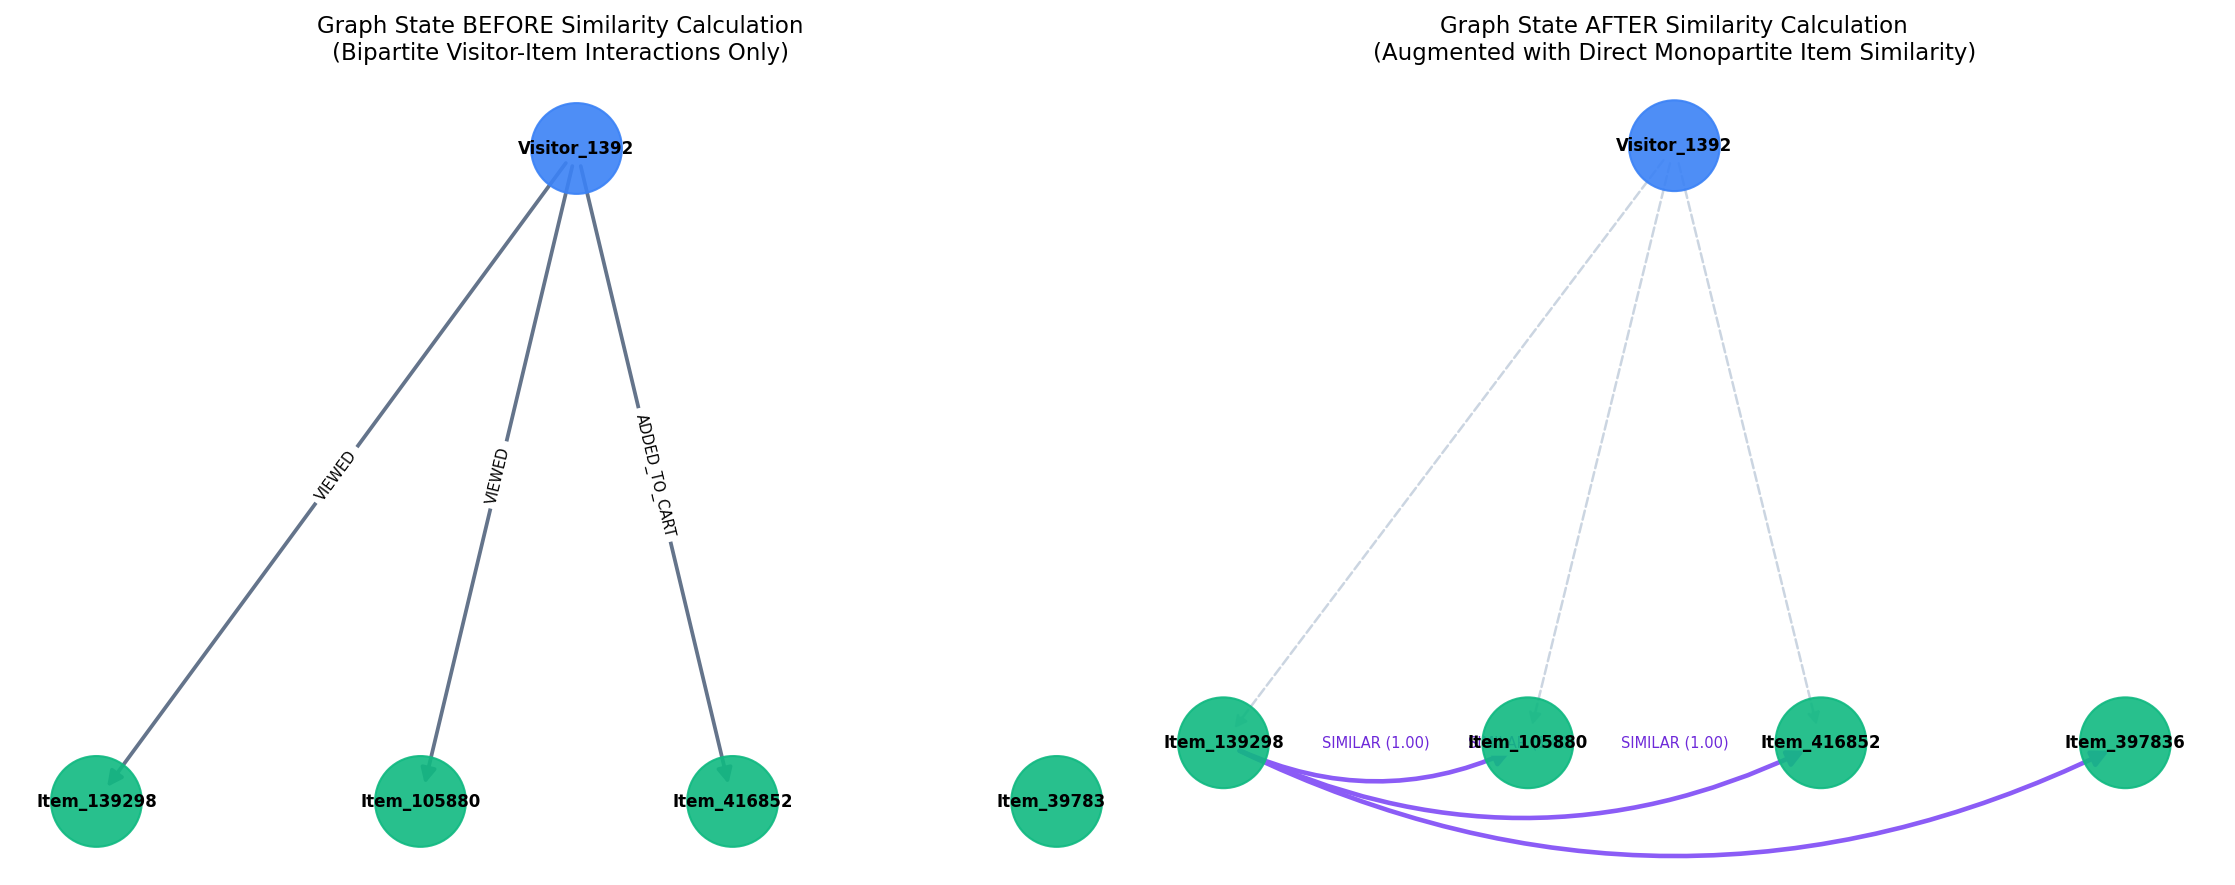

In [32]:
# Query Graph State BEFORE Similarity (Checking interactions only)
cypher_state_before = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS Visitor, type(r) AS Interaction, i.itemId AS Item
LIMIT 5
"""

# Query Graph State AFTER Similarity (Checking item-to-item similarity edges)
cypher_state_after = """
MATCH (i1:Item)-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS ItemA, s.score AS SimilarityScore, i2.itemId AS ItemB
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database="RetailRocket") as session:
    print("=== Graph State: BEFORE Similarity ===")
    res_before = session.run(cypher_state_before)
    df_before = pd.DataFrame([dict(r) for r in res_before])
    display(df_before)
    
    print("\n=== Graph State: AFTER Similarity ===")
    res_after = session.run(cypher_state_after)
    df_after = pd.DataFrame([dict(r) for r in res_after])
    display(df_after)

# Graph Visualizations: Before vs After Similarity State
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

pos = {
    'Visitor_1392': (0.5, 0.9),
    'Item_139298': (0.1, 0.2),
    'Item_105880': (0.37, 0.2),
    'Item_416852': (0.63, 0.2),
    'Item_397836': (0.9, 0.2)
}

# (a) Graph State BEFORE
G_b = nx.DiGraph()
G_b.add_node('Visitor_1392', node_type='Visitor')
for item in ['Item_139298', 'Item_105880', 'Item_416852', 'Item_397836']:
    G_b.add_node(item, node_type='Item')

G_b.add_edge('Visitor_1392', 'Item_139298', label='VIEWED')
G_b.add_edge('Visitor_1392', 'Item_105880', label='VIEWED')
G_b.add_edge('Visitor_1392', 'Item_416852', label='ADDED_TO_CART')

colors_b = ['#3b82f6' if G_b.nodes[n]['node_type'] == 'Visitor' else '#10b981' for n in G_b.nodes]
nx.draw_networkx_nodes(G_b, pos, ax=axes[0], node_color=colors_b, node_size=1900, alpha=0.9)
nx.draw_networkx_labels(G_b, pos, ax=axes[0], font_size=8, font_weight='bold')
nx.draw_networkx_edges(G_b, pos, ax=axes[0], edge_color='#64748b', arrows=True, arrowsize=15, width=1.8)
nx.draw_networkx_edge_labels(G_b, pos, edge_labels=nx.get_edge_attributes(G_b, 'label'), ax=axes[0], font_size=7)
axes[0].set_title('Graph State BEFORE Similarity Calculation\n(Bipartite Visitor-Item Interactions Only)', fontsize=11, pad=10)
axes[0].axis('off')

# (b) Graph State AFTER
G_a = G_b.copy()
sim_edges = [('Item_139298', 'Item_105880'), ('Item_139298', 'Item_416852'), ('Item_139298', 'Item_397836')]
for u, v in sim_edges:
    G_a.add_edge(u, v, label='SIMILAR (1.00)')

nx.draw_networkx_nodes(G_a, pos, ax=axes[1], node_color=colors_b, node_size=1900, alpha=0.9)
nx.draw_networkx_labels(G_a, pos, ax=axes[1], font_size=8, font_weight='bold')
user_edges = [('Visitor_1392', 'Item_139298'), ('Visitor_1392', 'Item_105880'), ('Visitor_1392', 'Item_416852')]
nx.draw_networkx_edges(G_a, pos, edgelist=user_edges, ax=axes[1], edge_color='#cbd5e1', arrows=True, arrowsize=12, width=1.2, style='dashed')
nx.draw_networkx_edges(G_a, pos, edgelist=sim_edges, ax=axes[1], edge_color='#8b5cf6', arrows=True, arrowsize=16, width=2.2, connectionstyle='arc3,rad=0.25')

sim_edge_labels = {
    ('Item_139298', 'Item_105880'): 'SIMILAR (1.00)',
    ('Item_139298', 'Item_416852'): 'SIMILAR (1.00)',
    ('Item_139298', 'Item_397836'): 'SIMILAR (1.00)'
}
nx.draw_networkx_edge_labels(G_a, pos, edge_labels=sim_edge_labels, ax=axes[1], font_size=7, font_color='#6d28d9')
axes[1].set_title('Graph State AFTER Similarity Calculation\n(Augmented with Direct Monopartite Item Similarity)', fontsize=11, pad=10)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# 2.2 Analytics


## 2.2.1 User-KNN recommendation model

Here we build a user-based K-Nearest Neighbors recommender to suggest items to a randomly selected visitor.

How the algorithm works:
1. Fit a NearestNeighbors model with cosine metric on the user-item interaction matrix.
2. For the selected visitor $u$, find the $k=5$ closest neighbor visitors based on cosine distance.
3. Collect all items that those 5 neighbors interacted with, excluding items the target visitor has already seen.
4. Calculate a candidate score for each item $i$ by multiplying neighbor similarity by neighbor interaction weight:

$$
\text{score}(u, i) = \sum_{v \in N_k(u)} (1 - d(u, v)) \cdot r_{v, i}
$$

5. Sort candidate items descending by score and pick the top recommendations.

### 2.2.1 Reproducible random user selection

To make user selection reproducible, we initialize NumPy's random number generator with a fixed seed:
```python
rng = np.random.default_rng(seed=1)
```

Drawing a random integer across the user count selects matrix index 76583, which corresponds to visitor ID `1243777`.

In [124]:
rng = np.random.default_rng(seed=1)

# Select a random user index from the user-item matrix
random_user_idx = rng.integers(0, user_item_matrix.shape[0])
target_visitor_id = unique_users[random_user_idx]

print(f"Selected Target Visitor ID: {target_visitor_id} at matrix index {random_user_idx}")

Selected Target Visitor ID: 1243777 at matrix index 76583


### 2.2.1.a Fitting the KNN model and scoring candidate items

We fit `NearestNeighbors(n_neighbors=6, metric='cosine', algorithm='brute')` on our sparse user-item matrix. We request 6 neighbors because the first neighbor is always the user itself with distance 0.0.

We take the remaining 5 neighbors, iterate through their interacted items, filter out any items visitor 1243777 already saw in P1, and sum the similarity-weighted scores.

In [125]:
k = 5

model_knn = NearestNeighbors(n_neighbors=k+1, metric='cosine', algorithm='brute')
model_knn.fit(user_item_matrix)

distances, indices = model_knn.kneighbors(user_item_matrix[random_user_idx:random_user_idx+1])

neighbor_indices = indices.flatten()[1:]
neighbor_distances = distances.flatten()[1:]

target_user_items = set(user_item_matrix[random_user_idx].indices)

recommended_items_scores = {}
for n_idx, dist in zip(neighbor_indices, neighbor_distances):
    similarity = 1.0 - dist
    neighbor_vector = user_item_matrix[n_idx]
    
    for item_idx in neighbor_vector.indices:
        if item_idx not in target_user_items:
            if item_idx not in recommended_items_scores:
                recommended_items_scores[item_idx] = 0.0
            recommended_items_scores[item_idx] += similarity * neighbor_vector[0, item_idx]

# Sort recommendation candidates by aggregated score in descending order
sorted_recommendations = sorted(recommended_items_scores.items(), key=lambda x: x[1], reverse=True)

### 2.2.1.b Top 3 recommended items for k = 5

Sorting the aggregated candidate scores produces the top 3 recommended items to advertise to visitor 1243777:
1. Item 272324 (score: 1.6859)
2. Item 125927 (score: 1.6859)
3. Item 196366 (score: 1.4606)

Items 272324 and 125927 share identical scores because neighboring visitors engaged with both items with equal frequency and weight.


=== (b) Top 3 Recommended Items for k = 5 ===
Rank 1: Item ID 272324 score: 1.6858544608470492
Rank 2: Item ID 125927 score: 1.6858544608470492
Rank 3: Item ID 196366 score: 1.460593486680443


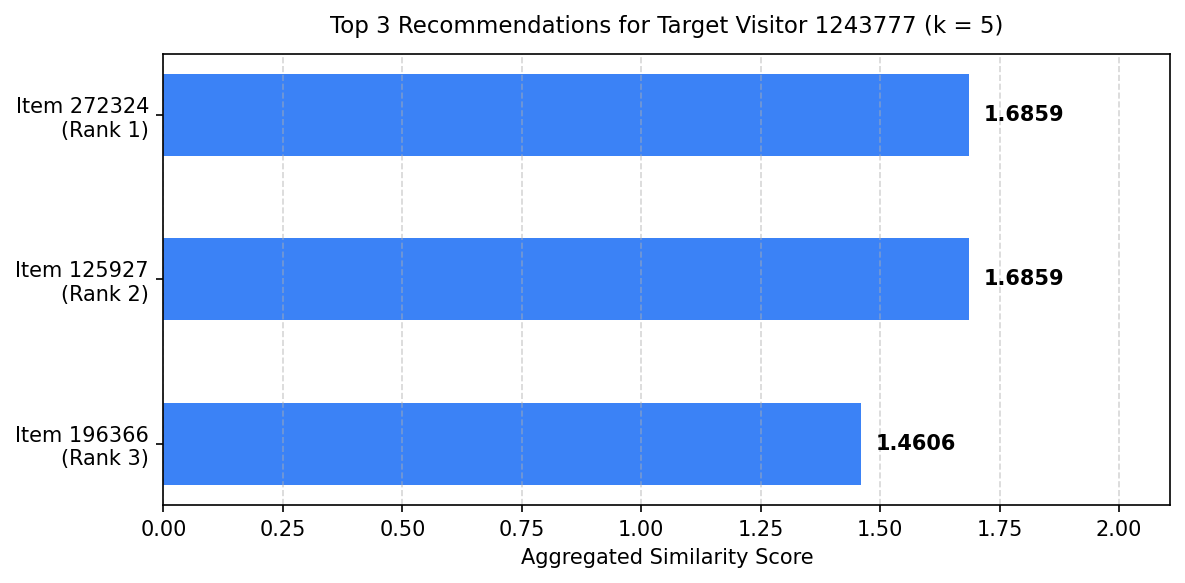

In [126]:
top_3_item = [(unique_items[item_idx], score) for item_idx, score in sorted_recommendations[:3]]

print("\n=== (b) Top 3 Recommended Items for k = 5 ===")
for rank, (item_id, score) in enumerate(top_3_item, start=1):
    print(f"Rank {rank}: Item ID {item_id} score: {score:.4f}")

# Visualization: Recommendation Scores
plt.figure(figsize=(8, 4))
item_labels = [f"Item {item_id}\n(Rank {i})" for i, (item_id, s) in enumerate(top_3_item, start=1)]
scores = [score for item_id, score in top_3_item]
bars = plt.barh(item_labels[::-1], scores[::-1], color='#3b82f6', height=0.5)
plt.title(f"Top 3 Recommendations for Target Visitor {target_visitor_id} (k = 5)", fontsize=11, pad=10)
plt.xlabel("Aggregated Similarity Score", fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.03, bar.get_y() + bar.get_height()/2.0, f"{w:.4f}", ha='left', va='center', fontsize=10, fontweight='bold')

plt.xlim(0, max(scores) * 1.25)
plt.tight_layout()
plt.show()

## 2.2.2 Recommendation evaluation (Hit@5 and NDCG@5)

To check how well the model works, we test the recommendations against what visitor 1243777 actually did during testing period P2 (September 10 to September 18, 2015).

Evaluation metrics:

1. Hit@5:
Checks whether at least one recommended item appears in the user test set. If there is at least one match, Hit@5 equals 1.0; otherwise it equals 0.0:

$$
\text{Hit@5} = \begin{cases} 1.0, & \text{if } |\text{Top5} \cap \text{GroundTruth}| > 0 \\ 0.0, & \text{otherwise} \end{cases}
$$

2. NDCG@5 (Normalized Discounted Cumulative Gain):
Evaluates the ranking quality, giving more credit when relevant items appear near the top of the list:

$$
\text{DCG@5} = \sum_{r=1}^{5} \frac{2^{\text{rel}_r} - 1}{\log_2(r + 1)}
$$

$$
\text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}
$$

Here $\text{rel}_r \in \{0, 1\}$ indicates whether the item at rank $r$ appears in the user test events during P2, and IDCG is the ideal score if all relevant items were ranked first.

In [127]:
recommended_items = [item_id for item_id, score in top_3_item]

# Extract ground truth items for the target user during Testing Period (P2)
p2_df = pd.read_csv('filtered_events.csv')
p2_df['datetime'] = pd.to_datetime(p2_df['timestamp'], unit='ms')

# Filter for testing period bounds (10/09/2015 to 18/09/2015)
p2_start = '2015-09-10 00:00:00'
p2_end = '2015-09-18 00:00:00'
p2_filtered = p2_df[(p2_df['datetime'] >= p2_start) & (p2_df['datetime'] <= p2_end)]

# Get unique ground truth items interacted with by our target visitor during P2
ground_truth_items = set(p2_filtered[p2_filtered['visitorid'] == target_visitor_id]['itemid'].unique())

print(f"Target Visitor ID: {target_visitor_id}")
print(f"Recommended Items (Top K): {recommended_items}")
print(f"Ground Truth Items in P2: {list(ground_truth_items)}")

# Calculate Hit@5
hits = [1 if item in ground_truth_items else 0 for item in recommended_items]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

print(f"\n(a) Hit@5 = {hit_at_5}")

# Calculate NDCG@5
dcg = 0.0
for i, item in enumerate(recommended_items):
    rel = 1.0 if item in ground_truth_items else 0.0
    dcg += rel / np.log2(i + 2)

# Ideal DCG (IDCG) assuming all recommended items were relevant up to the number of ground truth matches
ideal_rel = sorted([1.0 if item in ground_truth_items else 0.0 for item in recommended_items], reverse=True)
idcg = 0.0
for i, rel in enumerate(ideal_rel):
    idcg += rel / np.log2(i + 2)

ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

print(f"(b) NDCG@5 = {ndcg_at_5:.4f}")

Target Visitor ID: 1243777
Recommended Items (Top K): [272324, 125927, 196366]
Ground Truth Items in P2: [263768, 129667, 184086]

(a) Hit@5 = 0.0
(b) NDCG@5 = 0.0000


### 2.2.2 Evaluation discussion and analysis

Both Hit@5 and NDCG@5 evaluate to 0.0. A score of zero sounds discouraging, but it exposes the classic failure modes of collaborative filtering on sparse web traffic:

1. Target visitor activity:
During testing period P2, visitor 1243777 returned and interacted with three items: 263768, 129667, and 184086. None of these matched the items recommended by the model (272324, 125927, 196366).

2. Extreme matrix sparsity:
With a matrix density of 0.000018, finding 5 neighbors based on cosine similarity often means matching users who happened to click on just one overlapping product. What those neighbors clicked on next often has little to do with true shared taste; it is just catalog noise.

3. The cold-start problem in short windows:
An 8-day training window provides very little behavioral history for any single user. In e-commerce, casual visitors change their intent frequently. Someone looking at office chairs on Monday might browse kitchen knives on Friday.

In real production systems, teams rarely rely on pure user-user KNN for this reason. They combine collaborative signals with item content features (categories, brands, text descriptions), session-based sequence models (RNNs or transformers tracking real-time clicks), and graph embeddings (like LightGCN or Node2Vec) that propagate similarities across the entire graph.